# ResNet18: transfer learning on CIFAR-10

**Learning outcomes:** prepare a reproducible dataset, inspect tensor shapes,
train a classifier, select a checkpoint using validation data, and evaluate on
a separate test set. All class names and plots in this edition are in English.

Run cells from top to bottom. The first dataset/model download requires internet.
CPU mode works; set `COURSE_SMOKE=1` before starting the kernel for a short pipeline check.
A smoke-test score is not a measure of model quality.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('torch').split("+")[0] == '2.14.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('torch' + ":", version('torch'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.12
torch: 2.14.1
Run mode: Default classroom training parameters


**Expected output:**

```text
Python: 3.12.12
torch: 2.14.1
Run mode: Default classroom training parameters
```

In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'/Users/will/workspace/deep-learning-lab/english/data/torch-cache'

**Expected output:**

```text
'…/deep-learning-lab/english/data/torch-cache'
```

(Inside the quoted output `…` stands for the repository's absolute path prefix on the machine that ran the notebook; yours will show your own path.)

In [3]:
EXPERIMENT = "resnet-cifar10"

import random
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
DATA = COURSE / "01-image-classification" / "data"
OUTPUT = COURSE / "01-image-classification" / "outputs" / EXPERIMENT
DATA.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
EPOCHS = 1 if SMOKE else 3
BATCH_SIZE = 32 if SMOKE else 64
print(f"Device: {DEVICE}; experiment: {EXPERIMENT}; smoke test: {SMOKE}")

Device: mps; experiment: resnet-cifar10; smoke test: False


**Expected output:**

```text
Device: mps; experiment: resnet-cifar10; smoke test: False
```

## 1. Prepare training, validation, and test data

Keep the official test split untouched until final evaluation. Create validation
data only from the training split. The fixed seed controls the split. A classroom
run uses a subset to keep runtime manageable; increase limits for a fuller experiment.

In [4]:
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
CHANNELS, IMAGE_SIZE = 3, 224
transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
from vision_data import load_cifar10
full_train = load_cifar10(DATA / "cifar10", train=True, transform=transform)
test_set = load_cifar10(DATA / "cifar10", train=False, transform=transform)

val_size = len(full_train) // 10
train_set, val_set = random_split(full_train, [len(full_train) - val_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))
train_set = Subset(train_set, range(min(len(train_set), 64 if SMOKE else 4000)))
val_set = Subset(val_set, range(min(len(val_set), 32 if SMOKE else 1000)))
test_set = Subset(test_set, range(min(len(test_set), 32 if SMOKE else 1000)))

Batch shape: (64, 3, 224, 224) Label shape: (64,)
Split sizes: 4000 1000 1000


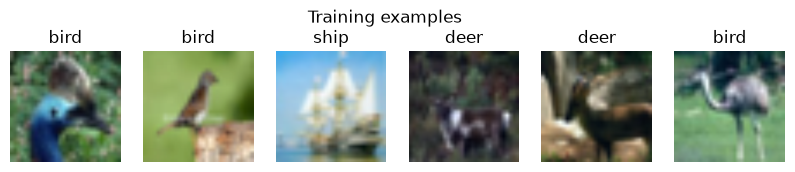

In [5]:
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape), "Label shape:", tuple(labels.shape))
print("Split sizes:", len(train_set), len(val_set), len(test_set))
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for axis, image, label in zip(axes, images, labels):
    view = image[0] if CHANNELS == 1 else image.permute(1, 2, 0)
    view = (view - view.min()) / (view.max() - view.min() + 1e-8)
    axis.imshow(view, cmap="gray" if CHANNELS == 1 else None)
    axis.set_title(CLASS_NAMES[int(label)])
    axis.axis("off")
fig.suptitle("Training examples")
plt.show()

**Expected output:**

```text
Batch shape: (64, 3, 224, 224) Label shape: (64,)
Split sizes: 4000 1000 1000
```

**Expected output (image):**

![Prepare training, validation, and test data](../assets/03-resnet-cifar10-1.png)

*Prepare training, validation, and test data*

## 2. Define the model

A convolution learns local features with shared weights. Pooling reduces spatial
size; the final linear layer returns one logit per class. Cross-entropy expects
logits, so softmax is used only when displaying prediction probabilities.

### Transfer learning with ResNet18

Residual connections add an identity shortcut to learned transformations.
This lesson freezes the pretrained backbone and trains a new ten-class head.
Batch-normalization statistics also stay fixed. Use ImageNet normalization;
input images are resized to 224 by 224. A smoke run uses random weights and
cannot demonstrate transfer-learning performance.

In [6]:
# Smoke mode checks wiring without downloading pretrained weights.
weights = None if SMOKE else models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
for parameter in model.parameters():
    parameter.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
model = model.to(DEVICE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 5130


**Expected output:**

```text
Trainable parameters: 5130
```

## 3. Train and select a checkpoint

Training enables gradients and updates parameters. Evaluation disables gradients
and switches dropout/batch normalization to evaluation behavior. Save the checkpoint
with the highest validation accuracy; never choose it using test accuracy.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=0.001)

def run_epoch(loader, training=False):
    model.eval()  # Keep frozen backbone batch statistics fixed.
    model.fc.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

history, best_accuracy = [], -1.0
checkpoint = OUTPUT / "best_model.pt"
for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader)
    history.append([train_loss, val_loss, train_accuracy, val_accuracy])
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint)
    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"validation loss {val_loss:.4f} | validation accuracy {val_accuracy:.3f}")

Epoch 1/3 | train loss 1.4207 | validation loss 0.8782 | validation accuracy 0.763


Epoch 2/3 | train loss 0.7053 | validation loss 0.6559 | validation accuracy 0.799


Epoch 3/3 | train loss 0.5586 | validation loss 0.5736 | validation accuracy 0.806


**Expected output:**

```text
Epoch 1/3 | train loss 1.4207 | validation loss 0.8782 | validation accuracy 0.763
Epoch 2/3 | train loss 0.7053 | validation loss 0.6559 | validation accuracy 0.799
Epoch 3/3 | train loss 0.5586 | validation loss 0.5736 | validation accuracy 0.806
```

## 4. Evaluate the saved checkpoint

Held-out test accuracy: 0.836


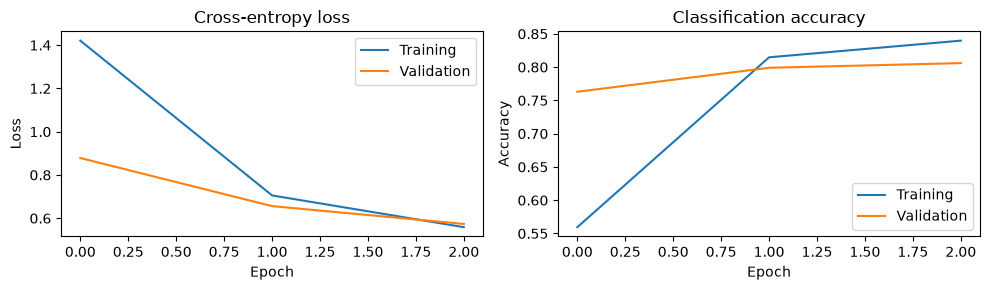

In [8]:
import json
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
test_loss, test_accuracy = run_epoch(test_loader)
print(f"Held-out test accuracy: {test_accuracy:.3f}")
metrics = {"test_accuracy": test_accuracy, "test_loss": test_loss,
           "best_validation_accuracy": best_accuracy, "seed": SEED,
           "smoke_test": SMOKE, "epochs": EPOCHS, "classes": CLASS_NAMES}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
values = np.asarray(history)
axes[0].plot(values[:, 0], label="Training")
axes[0].plot(values[:, 1], label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(values[:, 2], label="Training")
axes[1].plot(values[:, 3], label="Validation")
axes[1].set(title="Classification accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "training_curves.png")
plt.show()

**Expected output:**

```text
Held-out test accuracy: 0.836
```

**Expected output (image):**

![Evaluate the saved checkpoint](../assets/03-resnet-cifar10-2.png)

*Evaluate the saved checkpoint*

## 5. Inspect errors and predict one image

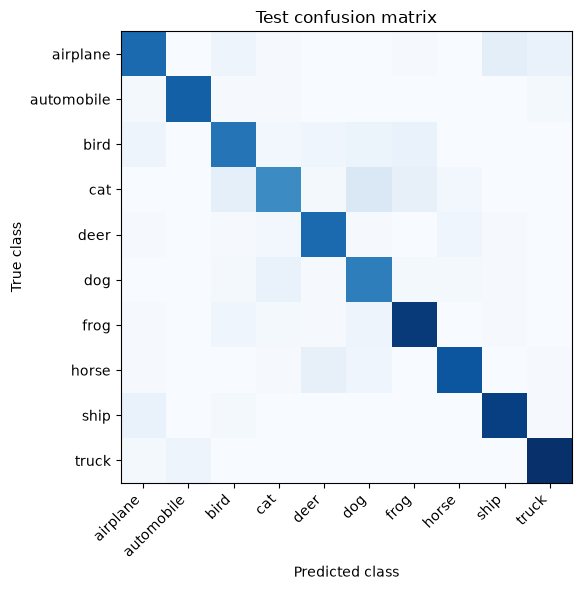

Misclassified example: true=cat, predicted=dog
Misclassified example: true=airplane, predicted=bird
Misclassified example: true=bird, predicted=dog
Misclassified example: true=deer, predicted=cat
Misclassified example: true=deer, predicted=airplane
Misclassified example: true=cat, predicted=dog
Prediction: dog | confidence: 0.427 | true label: cat


In [9]:
confusion = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)
mistakes = []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(DEVICE)).argmax(1).cpu()
        for image, true, predicted in zip(images, labels, predictions):
            confusion[int(true), int(predicted)] += 1
            if true != predicted and len(mistakes) < 6:
                mistakes.append((image, int(true), int(predicted)))
fig, axis = plt.subplots(figsize=(7, 6))
axis.imshow(confusion, cmap="Blues")
axis.set(xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)),
         xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
         xlabel="Predicted class", ylabel="True class", title="Test confusion matrix")
plt.setp(axis.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(OUTPUT / "confusion_matrix.png")
plt.show()
for _, true, predicted in mistakes:
    print(f"Misclassified example: true={CLASS_NAMES[true]}, predicted={CLASS_NAMES[predicted]}")

# Single-image inference uses the same preprocessing as evaluation.
image, true_label = test_set[0]
with torch.no_grad():
    probabilities = model(image.unsqueeze(0).to(DEVICE)).softmax(1)[0].cpu()
prediction = int(probabilities.argmax())
print(f"Prediction: {CLASS_NAMES[prediction]} | confidence: {probabilities[prediction]:.3f} | "
      f"true label: {CLASS_NAMES[int(true_label)]}")

**Expected output:**

```text
Misclassified example: true=cat, predicted=dog
Misclassified example: true=airplane, predicted=bird
Misclassified example: true=bird, predicted=dog
Misclassified example: true=deer, predicted=cat
Misclassified example: true=deer, predicted=airplane
Misclassified example: true=cat, predicted=dog
Prediction: dog | confidence: 0.427 | true label: cat
```

**Expected output (image):**

![Inspect errors and predict one image](../assets/03-resnet-cifar10-3.png)

*Inspect errors and predict one image*

## Exercises and discussion

1. Predict each tensor shape before running the model.
2. Compare learning rates while keeping the split fixed.
3. Explain why validation and test results can differ.
4. Inspect misclassified examples before increasing model size.
5. For a new image, apply exactly the evaluation preprocessing and class mapping.

The model weights, class names, seed, and metrics are stored under this experiment's
output directory. Results depend on the subset, hardware, and training duration.